In [40]:
import sys
sys.path.append("./../")
import os
import numpy as np
from utils import BEST_DATASET_PARAMETERS

results_root = "./../saved_results"
res = {}

for method in os.listdir(f"{results_root}/baselines/"):
    res[method] = {}
    for dataset in os.listdir(f"{results_root}/baselines/{method}"):
        res[method][dataset] = {}
        for file in os.listdir(f"{results_root}/baselines/{method}/{dataset}"):
            if "exp_results" not in file:
                continue
            with open(f"{results_root}/baselines/{method}/{dataset}/{file}", "r") as f:
                lines = f.readlines()
            cov = [float(l.split(",")[1]) for l in lines[-6:] if "Experiment " in l]
            prox = [float(l.split(",")[2]) for l in lines[-6:] if "Experiment " in l]
            prox = [p for p in prox if p != -1]
            if "cov" not in res[method][dataset] or np.mean(cov) > res[method][dataset]['cov']:
                res[method][dataset]['cov'] = cov
                res[method][dataset]['prox'] = prox

res["gcsgnn"] = {}
for dataset in os.listdir(f"{results_root}/gcsgnn"):
    res["gcsgnn"][dataset] = {}
    param = BEST_DATASET_PARAMETERS[dataset]
    file = f"exp_results_lr={param['lr']}_wd={param['wd']}_epochs={param['epochs']}_spc={param['spc']}_spd={param['spd']}_edo={param['edo']}_ddo={param['ddo']}_s=20.txt"
    with open(f"{results_root}/gcsgnn/{dataset}/{file}", "r") as f:
        lines = f.readlines()
    cov = [float(l.split(",")[1]) for l in lines[-6:] if "Experiment " in l]
    prox = [float(l.split(",")[2]) for l in lines[-6:] if "Experiment " in l]
    prox = [p for p in prox if p != -1]
    res["gcsgnn"][dataset]['cov'] = cov
    res["gcsgnn"][dataset]['prox'] = prox

In [41]:
methods = ['cf_gnnexplainer', 'gcf_explainer', 'gnn_explainer', 'induce', 'protgnn', 'rcexplainer', 'gcsgnn']
datasets = ['AIDS', 'BZR_MD', 'MUTAG', 'CIFAR10', 'MNIST']
for d in datasets:
    cov, prox = "", ""
    for m in methods:
        if d in res[m]:
            if len(res[m][d]['prox']) > 0:
                cov += f"{np.round(np.mean(res[m][d]['cov']), 2):.2f} ± {np.round(np.std(res[m][d]['cov']), 2):.2f}\t"
                prox += f"{np.round(np.mean(res[m][d]['prox']), 2):.2f} ± {np.round(np.std(res[m][d]['prox']), 2):.2f}\t"
            else:
                cov += f"{np.round(np.mean(res[m][d]['cov']), 2):.2f} ± {np.round(np.std(res[m][d]['cov']), 2):.2f}\t"
                prox += "N/A\t\t"
        else:
            cov += "OOT\t\t"
            prox += "OOT\t\t"
    print(cov)
    print(prox)

0.00 ± 0.00	2.82 ± 0.93	0.00 ± 0.00	0.00 ± 0.00	0.00 ± 0.00	0.04 ± 0.03	80.28 ± 12.65	
N/A		8.10 ± 0.23	N/A		N/A		N/A		4.69 ± 1.80	16.31 ± 1.56	
25.38 ± 6.47	10.64 ± 2.91	67.05 ± 3.28	16.54 ± 11.08	0.00 ± 0.00	59.10 ± 4.89	93.72 ± 6.50	
12.18 ± 0.29	5.92 ± 0.57	19.10 ± 0.06	4.52 ± 0.91	N/A		9.75 ± 0.24	15.14 ± 0.68	
0.48 ± 0.65	34.52 ± 6.81	87.58 ± 2.58	0.65 ± 0.79	0.00 ± 0.00	26.61 ± 3.71	99.84 ± 0.32	
10.25 ± 0.18	8.79 ± 0.37	17.98 ± 0.05	5.62 ± 1.18	N/A		8.65 ± 0.20	14.15 ± 0.49	
0.18 ± 0.12	OOT		63.38 ± 8.73	0.00 ± 0.00	12.64 ± 11.07	6.78 ± 2.50	85.92 ± 18.40	
66.35 ± 0.25	OOT		110.44 ± 0.76	N/A		116.12 ± 1.14	56.31 ± 0.04	21.45 ± 13.13	
1.99 ± 0.27	OOT		98.49 ± 0.10	0.12 ± 0.09	0.00 ± 0.00	3.93 ± 0.72	97.80 ± 2.72	
85.21 ± 0.22	OOT		98.13 ± 0.00	78.19 ± 1.53	N/A		83.63 ± 0.23	42.63 ± 8.08	


In [ ]:
import sys
sys.path.append("./../")
import os
import numpy as np
from utils import BEST_DATASET_PARAMETERS

results_root = "./../saved_results"
res = {}

for method in os.listdir(f"{results_root}/baselines/"):
    res[method] = {}
    for dataset in os.listdir(f"{results_root}/baselines/{method}"):
        for file in os.listdir(f"{results_root}/baselines/{method}/{dataset}"):
            if "exp_results" not in file:
                continue
            with open(f"{results_root}/baselines/{method}/{dataset}/{file}", "r") as f:
                lines = f.readlines()
            time = [float(l.split(",")[-1].split("s")[0]) for l in lines[-6:] if "Experiment " in l]
            if dataset not in res[method] or np.mean(time) < res[method][dataset]:
                res[method][dataset] = time

res["gcsgnn"] = {}
for dataset in os.listdir(f"{results_root}/gcsgnn"):
    res["gcsgnn"][dataset] = {}
    param = BEST_DATASET_PARAMETERS[dataset]
    file = f"exp_results_lr={param['lr']}_wd={param['wd']}_epochs={param['epochs']}_spc={param['spc']}_spd={param['spd']}_edo={param['edo']}_ddo={param['ddo']}_s=20.txt"
    with open(f"{results_root}/gcsgnn/{dataset}/{file}", "r") as f:
        lines = f.readlines()
    time = [float(l.split(",")[-1].split("s")[0]) for l in lines[-6:] if "Experiment " in l]
    res["gcsgnn"][dataset] = time

In [45]:
methods = ['cf_gnnexplainer', 'gcf_explainer', 'gnn_explainer', 'induce', 'protgnn', 'rcexplainer', 'gcsgnn']
datasets = ['AIDS', 'BZR_MD', 'MUTAG', 'CIFAR10', 'MNIST']
for d in datasets:
    line = ""
    for m in methods:
        if d in res[m]:
            line += f"{np.round(np.mean(res[m][d]), 2):,.2f} ± {np.round(np.std(res[m][d]), 2):,.2f}\t"
        else:
            line += "OOT\t\t"
    print(line)


3,911.09 ± 94.99	2,173.32 ± 82.64	2,561.93 ± 49.07	2,872.43 ± 557.82	644.84 ± 30.83	41.88 ± 6.53	97.95 ± 1.45	
481.86 ± 37.18	2,134.66 ± 58.25	314.54 ± 38.68	453.65 ± 58.94	71.32 ± 12.21	46.58 ± 78.53	14.77 ± 1.76	
328.89 ± 8.09	2,593.18 ± 350.40	216.51 ± 7.65	414.91 ± 174.55	73.71 ± 1.81	6.39 ± 1.51	13.35 ± 2.40	
9,239.48 ± 615.23	OOT		4,943.47 ± 249.72	33,914.01 ± 10,590.64	339.11 ± 2.68	273.69 ± 15.21	2,546.38 ± 120.84	
8,042.88 ± 49.52	OOT		4,400.13 ± 91.52	31,880.21 ± 5,979.93	341.11 ± 11.42	281.17 ± 5.99	2,670.89 ± 124.87	


In [49]:
import sys
sys.path.append("./../")
import os
import numpy as np
from utils import BEST_DATASET_PARAMETERS

results_root = "./../saved_results"
res = {}
for dataset in os.listdir(f"{results_root}/gcsgnn"):
    res[dataset] = {"train_acc": [], "val_acc": [], "test_acc": []}
    param = BEST_DATASET_PARAMETERS[dataset]
    file = f"training_results_lr={param['lr']}_wd={param['wd']}_epochs={param['epochs']}_spc={param['spc']}_spd={param['spd']}_edo={param['edo']}_ddo={param['ddo']}_s=20_exp=exp-0.txt"
    for i in range(5):
        cur_file = file.replace("exp=exp-0", f"exp=exp-{i}")
        with open(f"{results_root}/gcsgnn/{dataset}/{cur_file}", "r") as f:
            lines = f.readlines()
        train_val_line = [l for l in lines if "best_train_loss" in l][-1].split(",")
        test_line = [l for l in lines if "test_loss" in l][-1].split(",")
        res[dataset]["train_acc"].append(float(train_val_line[1].split("=")[-1]) * 100)
        res[dataset]["val_acc"].append(float(train_val_line[4].split("=")[-1])* 100)
        res[dataset]["test_acc"].append(float(test_line[1].split("=")[-1])* 100)

In [50]:
datasets = ['AIDS', 'BZR_MD', 'MUTAG', 'CIFAR10', 'MNIST']
for d in datasets:
    line = ""
    for s in ["train_acc", "val_acc", "test_acc"]:
        line += f"{np.round(np.mean(res[d][s]), 2):,.2f} ± {np.round(np.std(res[d][s]), 2):,.2f}\t"
    print(line)

98.89 ± 0.36	98.12 ± 0.94	98.37 ± 0.59	
76.27 ± 0.90	68.80 ± 3.44	76.27 ± 3.09	
83.23 ± 3.09	87.50 ± 6.18	86.96 ± 2.38	
81.96 ± 1.38	80.68 ± 1.57	80.48 ± 2.31	
98.52 ± 0.17	98.48 ± 0.27	98.40 ± 0.38	


In [4]:
import sys
sys.path.append("./../")
from utils import BEST_DATASET_PARAMETERS

results_root = "./../saved_results"
epochs_y, spcs_y, spds_y = [], [], []
res = {"spc": [[2,3,4,5], []], "spd": [[1,2,3,4], []]}
d = 'BZR_MD'
best_params = BEST_DATASET_PARAMETERS[d]
file_path = f"{results_root}/gcsgnn/{d}/exp_results_lr={best_params['lr']}_wd={best_params['wd']}_epochs={best_params['epochs']}_spc={best_params['spc']}_spd={best_params['spd']}_edo={best_params['edo']}_ddo={best_params['ddo']}_s=20.txt"
for param in res:
    x = res[param][0]
    for val in x:
        cur_path = file_path.replace(f"{param}={best_params[param]}", f"{param}={val}")
        with open(cur_path) as f:
            lines = f.readlines()
        cov = [float(l.split(",")[1]) for l in lines[-6:] if "Experiment " in l]
        test_acc = []
        for i in range(5):
            with open(cur_path.replace("exp_results", "training_results").replace(".txt", f"_exp=exp-{i}.txt"), "r") as f:
                lines = f.readlines()
            test_line = [l for l in lines if "test_loss" in l][-1].split(",")
            test_acc.append(float(test_line[1].split("=")[-1])* 100)
        res[param][1].append({"cov": cov, "test_acc": test_acc})


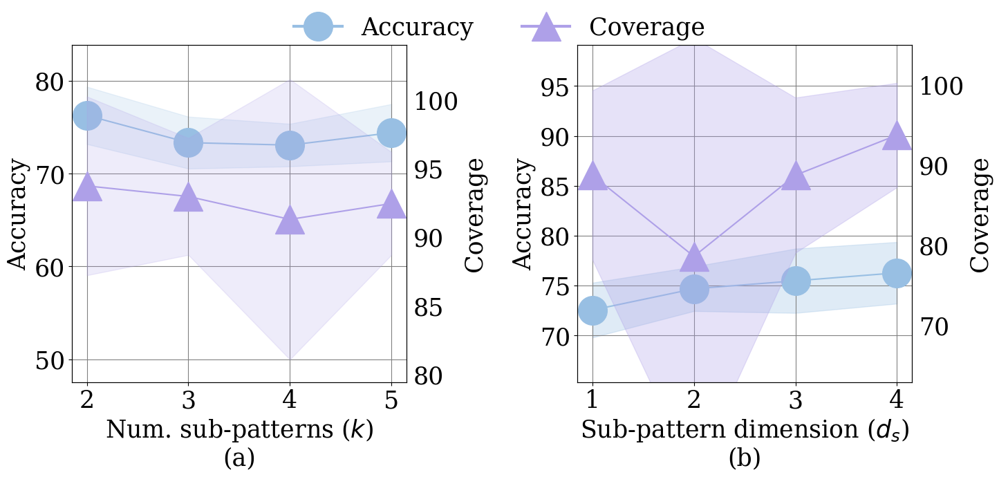

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rc('font',family='Times New Roman')

# Data
spc_x = res['spc'][0]
spd_x = res['spd'][0]

spc_cov_mean = np.array([np.mean(res['spc'][1][i]['cov']) for i in range(len(spc_x))])
spc_cov_var  = np.array([np.std(res['spc'][1][i]['cov']) for i in range(len(spc_x))])
spc_acc_mean = np.array([np.mean(res['spc'][1][i]['test_acc']) for i in range(len(spc_x))])
spc_acc_var = np.array([np.std(res['spc'][1][i]['test_acc']) for i in range(len(spc_x))])

spd_cov_mean= np.array([np.mean(res['spd'][1][i]['cov']) for i in range(len(spd_x))])
spd_cov_var = np.array([np.std(res['spd'][1][i]['cov']) for i in range(len(spd_x))])
spd_acc_mean = np.array([np.mean(res['spd'][1][i]['test_acc']) for i in range(len(spd_x))])
spd_acc_var = np.array([np.std(res['spd'][1][i]['test_acc']) for i in range(len(spd_x))])

# Creating 1x2 subplot
plt.rcParams['hatch.linewidth'] = 2.5
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams["font.size"] = 25
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# Plotting for first subplot
ax1.set_xticks(spc_x)
ax1.set_xlabel('Num. sub-patterns ($k$)')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(min(spc_acc_mean) * 0.65, max(spc_acc_mean) * 1.1)
ax1.set_facecolor("#ffffff")
ax1.grid(color='grey')
ax1.plot(spc_x, spc_acc_mean, color='#98bfe3', marker='o', linestyle='-', markersize=30, clip_on=False)  # Marking points as stars
ax1.tick_params(axis='y', which='both', labelleft=True, labelright=False)
ax1.fill_between(spc_x, spc_acc_mean - spc_acc_var, spc_acc_mean + spc_acc_var, color='#98bfe3', alpha=0.2)

ax1_twin = ax1.twinx()
ax1_twin.set_ylabel('Coverage')
ax1_twin.set_ylim(min(spc_cov_mean) * 0.87, 104)
ax1_twin.plot(spc_x, spc_cov_mean, color='#aea0e8', marker='^', linestyle='-', markersize=30)  # Marking points as triangles
ax1_twin.tick_params(axis='y', which='both', left=False, right=False, labelleft=False, labelright=True)
ax1_twin.fill_between(spc_x, spc_cov_mean - spc_cov_var, spc_cov_mean + spc_cov_var, color='#aea0e8', alpha=0.2)

ax2.set_xticks(spd_x)
ax2.set_xlabel('Sub-pattern dimension ($d_s$)')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(min(spd_acc_mean) * 0.9, max(spd_acc_mean) * 1.3)
ax2.set_facecolor("#ffffff")
ax2.grid(color='grey')
ax2.plot(spd_x, spd_acc_mean, color='#98bfe3', marker='o', linestyle='-', markersize=30, clip_on=False)  # Marking points as stars
ax2.tick_params(axis='y', which='both', labelleft=True, labelright=False)
ax2.fill_between(spd_x, spd_acc_mean - spd_acc_var, spd_acc_mean + spd_acc_var, color='#98bfe3', alpha=0.3)

ax2_twin = ax2.twinx()
ax2_twin.set_ylabel('Coverage')
ax2_twin.set_ylim(min(spd_cov_mean) * 0.8,105)
ax2_twin.plot(spd_x, spd_cov_mean, color='#aea0e8', marker='^', linestyle='-', markersize=30)  # Marking points as triangles
ax2_twin.tick_params(axis='y', which='both', left=False, right=False, labelleft=False, labelright=True)
ax2_twin.fill_between(spd_x, spd_cov_mean - spd_cov_var, spd_cov_mean + spd_cov_var, color='#aea0e8', alpha=0.3)

colors = ["#98bfe3", "#aea0e8"]
metrics = ['Accuracy', 'Coverage']
markers = ['o', '^']
line_styles = ['-', '-']
legend_handles = [Line2D([0], [0], color=color, marker=marker, linestyle=line_style, markersize=30, linewidth=3, label=metric)
                  for color, marker, line_style, metric in zip(colors, markers, line_styles, metrics)]
legend = fig.legend(handles=legend_handles, loc='upper center', ncol=len(metrics), fontsize=30, bbox_to_anchor=(0.5, 1.05), frameon=False, prop={"family":'DeJavu Serif'})
ax1.text(0.5, -0.19, '(a)', ha='center', va='top', transform=ax1.transAxes, fontsize=25)
ax2.text(0.5, -0.19, '(b)', ha='center', va='top', transform=ax2.transAxes, fontsize=25)

fig.tight_layout()
# Display the plot

plt.savefig('param_analysis.pdf', bbox_inches='tight')
plt.show()

In [23]:
import sys
sys.path.append("./../")
from utils import BEST_DATASET_PARAMETERS
import os

results_root = "./../saved_results"
datasets = ['AIDS', 'BZR_MD', 'MUTAG']
variants = ["nc", "nd", "ne", "np"]

res = {}
for d in datasets:
    res[d] = {}
    for v in variants:
        file_path = [f for f in os.listdir(f"{results_root}/ablation/{v}/{d}/") if "exp_results" in f][0]
        with open(f"{results_root}/ablation/{v}/{d}/{file_path}") as f:
            lines = f.readlines()
        res[d][v] = [float(l.split(",")[1]) for l in lines[-6:] if "Experiment " in l]
    best_params = BEST_DATASET_PARAMETERS[d]
    file_path = f"{results_root}/gcsgnn/{d}/exp_results_lr={best_params['lr']}_wd={best_params['wd']}_epochs={best_params['epochs']}_spc={best_params['spc']}_spd={best_params['spd']}_edo={best_params['edo']}_ddo={best_params['ddo']}_s=20.txt"
    with open(file_path) as f:
        lines = f.readlines()
    res[d]["orig"] = [float(l.split(",")[1]) for l in lines[-6:] if "Experiment " in l]

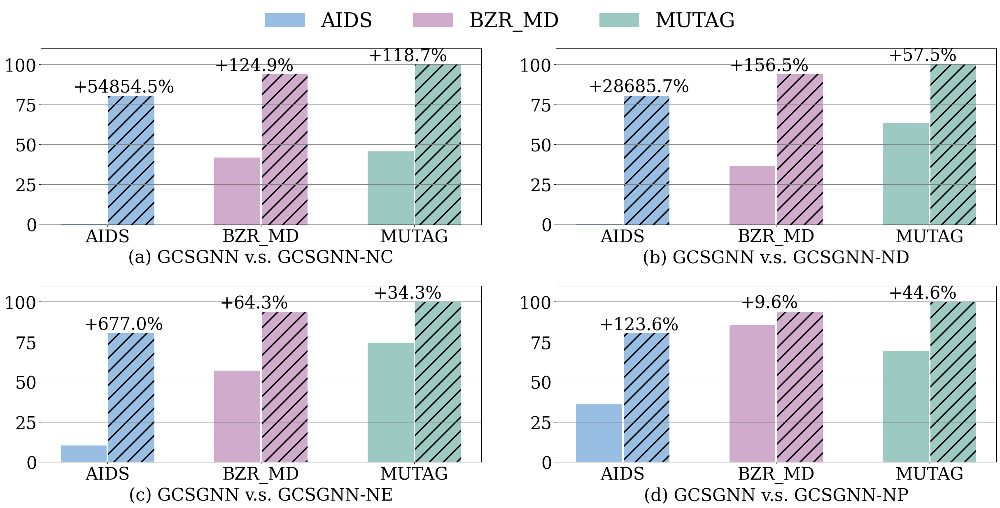

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# Data
datasets = ['AIDS', 'BZR_MD', 'MUTAG']
orig_vals = [np.mean(res[d]['orig']) for d in datasets]

custom_colors_new_order = ["#98bfe3", "#d0abcc", "#9cc9c2"] 

# Setting the hatch linewidth and font parameters
plt.rcParams['hatch.linewidth'] = 2.5
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams["font.size"] = 30

# Function to calculate the percentage lead of GlobalGCE
def calculate_percentage_lead(values_orig, values_other):
    return [(gce - other) / other * 100 if other != 0 else np.inf for gce, other in zip(values_orig, values_other)]

x = np.arange(len(datasets))
hatch_density = '/'  # Sparser hatching
bar_width = 0.3
bar_gap = 0.01

fig, axs = plt.subplots(2, 2, figsize=(25, 12))
for i, method in enumerate([m for m in res[datasets[0]] if m != "orig"]):
    row, col = int(i / 2), i % 2
    values_ablation = [np.mean(res[d][method]) for d in datasets]
    percentage_lead = calculate_percentage_lead(orig_vals, values_ablation)

    bars_ablation = axs[row][col].bar(x-bar_width/2-bar_gap/2, values_ablation, color=custom_colors_new_order, width=bar_width, alpha=1, label='GCSGNN-' + method.upper())
    bars_globalgce = axs[row][col].bar(x+bar_width/2+bar_gap/2, orig_vals, color=custom_colors_new_order, width=bar_width, alpha=1, hatch=hatch_density, label='GCSGNN')
    axs[row][col].set_xticks(x)
    axs[row][col].set_xticklabels(datasets)
    axs[row][col].yaxis.grid(color='grey')
    axs[row][col].set_ylim(0, 110)

    for j in range(len(datasets)):
        if j == 0:
            axs[row][col].text(x[j]  + bar_gap/2 + 0.1, max(orig_vals[j], values_ablation[j]), f'+{percentage_lead[j]:.1f}%', ha='center', va='bottom')
        else:
            axs[row][col].text(x[j] - bar_width/2 + bar_gap/2 + 0.1, max(orig_vals[j], values_ablation[j]), f'+{percentage_lead[j]:.1f}%', ha='center', va='bottom')
    axs[row][col].text(0.5, -0.14, f'({chr(97 + i)}) GCSGNN v.s. GCSGNN-{method.upper()}', ha='center', va='top', transform=axs[row][col].transAxes, fontsize=30)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=color, label=dataset) for color, dataset in zip(custom_colors_new_order, datasets)]

# Add legends outside the axes area
legend = fig.legend(handles=legend_handles, loc='upper center', ncol=len(datasets), fontsize=35, bbox_to_anchor=(0.5, 1.07), frameon=False)
# Save and display the plot
fig.tight_layout() 
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.17, hspace=None)
plt.savefig('ablations.pdf', bbox_inches='tight')
plt.show()

In [ ]:
import sys
sys.path.append("./../")
from data.data_utils import get_dataset
import pickle
from utils import BEST_DATASET_PARAMETERS
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

def tensor_to_pil_image(tensor):
    transform = transforms.Compose([
        transforms.Resize((200, 200)),
        transforms.ToPILImage()
    ])
    return transform(tensor)

results_root = "./../saved_results"
d = "MNIST"
dataset = get_dataset(d, 42, 20)
best_params = BEST_DATASET_PARAMETERS[d]
file_path = f"{results_root}/gcsgnn/{d}/cfs_lr={best_params['lr']}_wd={best_params['wd']}_epochs={best_params['epochs']}_spc={best_params['spc']}_spd={best_params['spd']}_edo={best_params['edo']}_ddo={best_params['ddo']}_s=20_exp=exp-0.pkl"
with open(file_path, "rb") as f:
    cfs = pickle.load(f)
dists = []
for cf_idx in range(best_params['spc']):
    dists.append([])
    for idx in [i for i in range(len(cfs)) if cfs[i]['cf_idx'] == cf_idx]:
        cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
        orig_graph = dataset.get_graph_idx(cfs[idx]['graph_idx'])
        dist = (cf_x - orig_graph['x']).pow(2).sum().sqrt()
        dists[cf_idx].append((dist, idx))
dists = [sorted(dist, key=lambda x: x[0]) for dist in dists]

In [2]:
imgs = []
for d in dists[0]:
    idx = d[1]
    cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
    imgs.append((tensor_to_pil_image(dataset[cfs[idx]['graph_idx']]['x'].reshape(20,20,1).permute(2,0,1)), tensor_to_pil_image(cf_x.reshape(20,20,1).permute(2,0,1))))
grid = Image.new('RGB', size=(400, len(imgs) * 200))
for i in range(len(imgs)):
    grid.paste(imgs[i][0], box=(0, i * 200))
    grid.paste(imgs[i][1], box=(200, i * 200))
grid

Maximum supported image dimension is 65500 pixels


In [3]:
idxs = [[dists[0][0][1], dists[0][3][1]], [dists[1][3][1], dists[1][7][1]], [dists[2][1][1], dists[2][2][1]]]
imgs = [[], [], []]
for x, row in enumerate(idxs):
    for y, idx in enumerate(row):
        cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
        grid = Image.new('RGB', size=(401, 200), color=(255,255,255))
        grid.paste(tensor_to_pil_image(dataset[cfs[idx]['graph_idx']]['x'].reshape(20,20,1).permute(2,0,1)), box=(0, 0))
        grid.paste(tensor_to_pil_image(cf_x.reshape(20,20,1).permute(2,0,1)), box=(201, 0))
        imgs[x].append(grid)

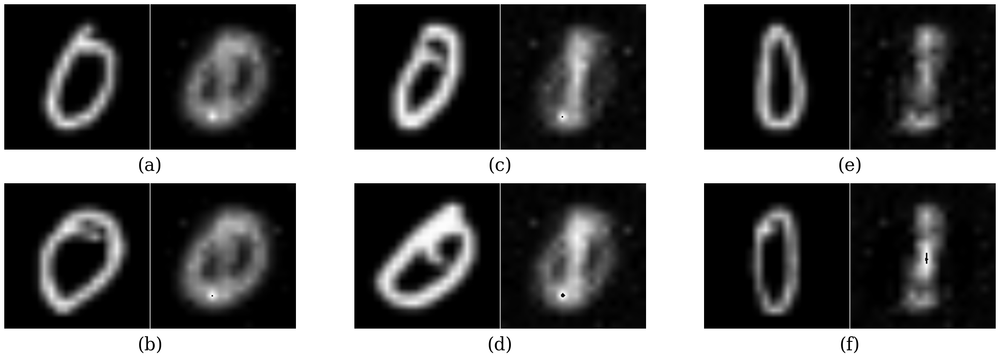

In [4]:
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams["font.size"] = 30

fig, ax = plt.subplots(2, 3, figsize=(30, 10))
for x, row in enumerate(imgs):
    for y, img in enumerate(row):
        ax[y][x].imshow(imgs[x][y])
        ax[y][x].axis('off')

ax[0][0].text(0.5, -0.05, '(a)', ha='center', va='top', transform=ax[0][0].transAxes, fontsize=30)
ax[1][0].text(0.5, -0.05, '(b)', ha='center', va='top', transform=ax[1][0].transAxes, fontsize=30)
ax[0][1].text(0.5, -0.05, '(c)', ha='center', va='top', transform=ax[0][1].transAxes, fontsize=30)
ax[1][1].text(0.5, -0.05, '(d)', ha='center', va='top', transform=ax[1][1].transAxes, fontsize=30)
ax[0][2].text(0.5, -0.05, '(e)', ha='center', va='top', transform=ax[0][2].transAxes, fontsize=30)
ax[1][2].text(0.5, -0.05, '(f)', ha='center', va='top', transform=ax[1][2].transAxes, fontsize=30)

plt.savefig('case_study.pdf', bbox_inches='tight')


In [5]:
import sys
sys.path.append("./../")
from data.data_utils import get_dataset
import pickle
from utils import BEST_DATASET_PARAMETERS
from torchvision import transforms
from PIL import Image

def tensor_to_pil_image(tensor):
    transform = transforms.Compose([
        transforms.Resize((200, 200)),
        transforms.ToPILImage()
    ])
    return transform(tensor)

results_root = "./../saved_results"
d = "MNIST"
dataset = get_dataset(d, 42, 20)
best_params = BEST_DATASET_PARAMETERS[d]
file_path = f"{results_root}/baselines/gnn_explainer/{d}/cfs_glr={best_params['lr']}_gwd={best_params['wd']}_ge={best_params['epochs']}_exp=exp-0.pkl"
with open(file_path, "rb") as f:
    cfs = pickle.load(f)
dists = []
for idx in range(len(cfs)):
    cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
    orig_graph = dataset.get_graph_idx(cfs[idx]['graph_idx'])
    dist = (cf_x - orig_graph['x']).pow(2).sum().sqrt()
    dists.append((dist, idx))
dists = sorted(dists, key=lambda x: x[0])

In [6]:
imgs = []
for d in dists:
    idx = d[1]
    cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
    imgs.append((tensor_to_pil_image(dataset[cfs[idx]['graph_idx']]['x'].reshape(20,20,1).permute(2,0,1)), tensor_to_pil_image(cf_x.reshape(20,20,1).permute(2,0,1))))
grid = Image.new('RGB', size=(400, len(imgs) * 200))
for i in range(len(imgs)):
    grid.paste(imgs[i][0], box=(0, i * 200))
    grid.paste(imgs[i][1], box=(200, i * 200))
grid

Maximum supported image dimension is 65500 pixels


In [7]:
idxs = [dists[0][1], dists[int(len(dists) / 2)][1], dists[-1][1]]
imgs = []
for idx in idxs:
    cf_x = cfs[idx]['x'] * (cfs[idx]['x'] > 0).float()
    grid = Image.new('RGB', size=(401, 200), color=(255, 255, 255))
    grid.paste(tensor_to_pil_image(dataset[cfs[idx]['graph_idx']]['x'].reshape(20,20,1).permute(2,0,1)), box=(0, 0))
    grid.paste(tensor_to_pil_image(cf_x.reshape(20,20,1).permute(2,0,1)), box=(201, 0))
    imgs.append(grid)

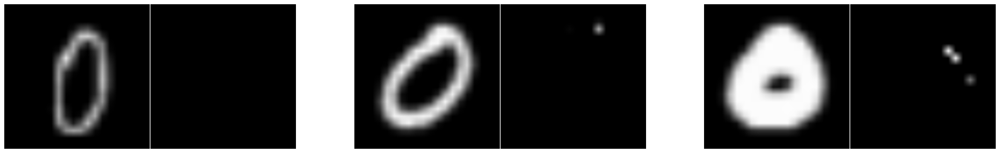

In [8]:
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams["font.size"] = 30

fig, ax = plt.subplots(1, 3, figsize=(30, 10))
for x in range(len(imgs)):
    ax[x].imshow(imgs[x])
    ax[x].axis('off')

plt.savefig('case_study_gnnexplainer.pdf', bbox_inches='tight')